In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## hyperparameter-surface

**Figure 1: Validation loss over a 13 × 13 sweep of learning rate and weight decay.** Both axes are log scale; the circle marks the lowest loss in the sweep. Loss is lowest, 1.91, at learning rate 3.2e-4 and weight decay 5.6e-3, and training diverges at the largest learning rate, 1e-2, where loss rises to 3.76–4.55.

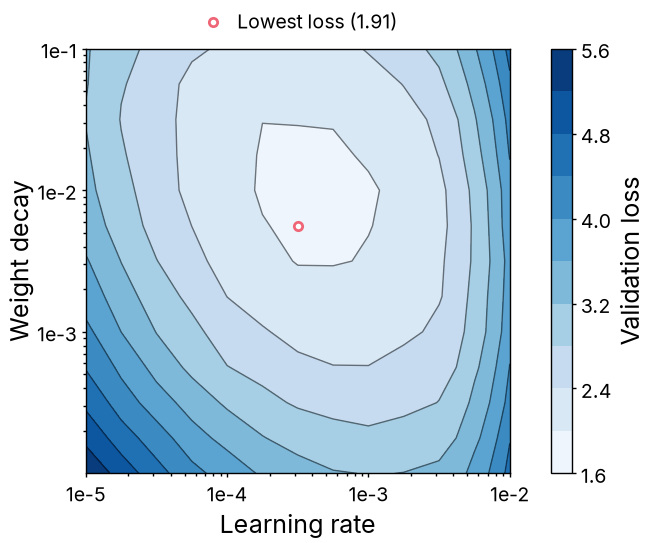

In [2]:
with open("../hyperparameter-surface.json") as f:
    data = json.load(f)
learning_rate = np.array(data["learning_rate"])
weight_decay = np.array(data["weight_decay"])
val_loss = np.array(data["val_loss"])
best_i, best_j = np.unravel_index(val_loss.argmin(), val_loss.shape)

fig, ax = plt.subplots(figsize=(3.25, 3))
cs = ax.contourf(learning_rate, weight_decay, val_loss, levels=10)
ax.contour(learning_rate, weight_decay, val_loss, levels=cs.levels, colors="black", linewidths=0.5, alpha=0.5)
fig.colorbar(cs, ax=ax, label="Validation loss")
ax.plot(learning_rate[best_j], weight_decay[best_i], "o", color=colors["ours"],
        label=f"Lowest loss ({val_loss[best_i, best_j]:.3g})")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([1e-5, 1e-4, 1e-3, 1e-2], labels=["1e-5", "1e-4", "1e-3", "1e-2"])
ax.set_yticks([1e-3, 1e-2, 1e-1], labels=["1e-3", "1e-2", "1e-1"])
ax.set_xlabel("Learning rate")
ax.set_ylabel("Weight decay")
ax.grid(False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0.5, frameon=False)

fit_height(fig, ax, aspect=1.0)
fig.savefig("hyperparameter-surface.pdf")
fig.savefig("hyperparameter-surface.png")
plt.show()